In [1]:
!git clone -q https://github.com/NX-AI/vision-lstm.git || true
!pip install -q einops

In [2]:
import os, sys, gc, glob, json, math, random, shutil, time, warnings
from copy import deepcopy

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

sys.path.insert(0, os.path.abspath("vision-lstm"))
from vision_lstm.vision_lstm2 import VisionLSTM2, MatrixLSTMCell

warnings.filterwarnings("ignore", message="passed mode=features")
warnings.filterwarnings("ignore", message="passed invalid pooling")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(torch.__version__, DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

2.11.0+cu128 cuda Tesla T4


## Config

In [ ]:
DRY_RUN = False          # True: tiny subset, 1 epoch, 1 seed, to check the pipeline end-to-end in ~5 min

SEEDS = [0, 1, 2]
VIEWS = 8                # cached augmentations per training image
EPOCHS = 30              
BATCH_SIZE = 64
LR = 3e-4
WEIGHT_DECAY = 0.05
WARMUP_FRAC = 0.05
LABEL_SMOOTHING = 0.1
HEAD_DROPOUT = 0.1
CLIP = 1.0
USE_AMP = True           
TIME_BUDGET_H = 11.0     
PHASES = (1,2)           
BENCH_STEPS = 30

NUM_TVERSKY_FEATURES = 64   # as in HybridTverskyViL
TVERSKY_OUTPUT_DIM = 64     # as in convert_vil_to_tversky

BASE_VIL = {
    "dim": 256,
    "depth": 6,
    "patch_size": 16,
    "input_shape": (3, 224, 224),
    "mode": "features",
    "pooling": "bilateral_flatten",
    "drop_path_rate": 0.0,
}

# Arms, in priority order. dim="match:<arm>" picks the width whose param count is closest to that arm.
ARMS = [
    # phase 1: the core claim
    dict(name="vil_d12",          phase=1, kind="standard", depth=12, dim=256),
    dict(name="tvy_d6_prod_ign",  phase=1, kind="tversky",  depth=6,  dim=256, inter="product", diff="ignorematch"),
    dict(name="vil_d6_wide",      phase=1, kind="standard", depth=6,  dim="match:tvy_d6_prod_ign"),
    dict(name="tvy_d6_prod_sub",  phase=1, kind="tversky",  depth=6,  dim=256, inter="product", diff="substractmatch"),
    # phase 2: same-shape control and intersection ablations
    dict(name="vil_d6",           phase=2, kind="standard", depth=6,  dim=256),
    dict(name="tvy_d6_min_ign",   phase=2, kind="tversky",  depth=6,  dim=256, inter="min",  diff="ignorematch"),
    dict(name="tvy_d6_mean_ign",  phase=2, kind="tversky",  depth=6,  dim=256, inter="mean", diff="ignorematch"),
]

OUT_DIR = "/kaggle/working" if os.path.exists("/kaggle/working") else "."
RESULTS = os.path.join(OUT_DIR, "results_vision.jsonl")
DATA_DIR = "/kaggle/temp/data" if os.path.exists("/kaggle") else "./data"

if DRY_RUN:
    SEEDS, VIEWS, EPOCHS, BENCH_STEPS = [0], 1, 1, 3
    RESULTS = os.path.join(OUT_DIR, "results_vision_dryrun.jsonl")

In [4]:
import random as _random

def set_seed(seed_value=42):
    _random.seed(seed_value)
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed_value)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

## Tversky similarity 


In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint


@torch.jit.script
def fused_tversky_score(a_fk: torch.Tensor,
                        b_fk: torch.Tensor,
                        constants: torch.Tensor,
                        diff_mode_sub: bool) -> torch.Tensor:
    # ORIGINAL (product intersection only). Kept verbatim as the reference implementation.
    mask_intersect = (a_fk > 0) & (b_fk > 0)
    intersection = torch.where(mask_intersect, a_fk * b_fk, 0.0)

    if diff_mode_sub:
        mask_ab = mask_intersect & (a_fk > b_fk)
        diff_ab = torch.where(mask_ab, a_fk - b_fk, 0.0)

        mask_ba = mask_intersect & (b_fk > a_fk)
        diff_ba = torch.where(mask_ba, b_fk - a_fk, 0.0)
    else:
        mask_ab = (a_fk > 0) & (b_fk <= 0)
        diff_ab = torch.where(mask_ab, a_fk, 0.0)

        mask_ba = (b_fk > 0) & (a_fk <= 0)
        diff_ba = torch.where(mask_ba, b_fk, 0.0)

    weighted_elements = (intersection * constants[0] +
                         diff_ab * constants[1] +
                         diff_ba * constants[2])

    return torch.sum(weighted_elements, dim=-1)


INTERSECTION_MODES = ("product", "min", "max", "mean", "gmean", "softmin")
MATMUL_INTERSECTIONS = ("product", "mean", "gmean")


def _psi(a, b, mode: str):
    """Intersection reduction Psi(a.f_k, b.f_k) from the paper (Eq. 3)."""
    if mode == "product":
        return a * b
    if mode == "min":
        return torch.minimum(a, b)
    if mode == "max":
        return torch.maximum(a, b)
    if mode == "mean":
        return 0.5 * (a + b)
    if mode == "gmean":
        return torch.sqrt((a * b).clamp_min(1e-8))
    if mode == "softmin":
        return -torch.logaddexp(-a, -b)
    raise ValueError(mode)


def tversky_score_pairwise(a_fk, b_fk, constants, intersection_mode: str, diff_mode_sub: bool):
    """Broadcast implementation, generalised to every intersection mode.
    With intersection_mode='product' this is exactly fused_tversky_score."""
    mask_intersect = (a_fk > 0) & (b_fk > 0)
    intersection = torch.where(mask_intersect, _psi(a_fk, b_fk, intersection_mode), 0.0)
    if diff_mode_sub:
        diff_ab = torch.where(mask_intersect & (a_fk > b_fk), a_fk - b_fk, 0.0)
        diff_ba = torch.where(mask_intersect & (b_fk > a_fk), b_fk - a_fk, 0.0)
    else:
        diff_ab = torch.where((a_fk > 0) & (b_fk <= 0), a_fk, 0.0)
        diff_ba = torch.where((b_fk > 0) & (a_fk <= 0), b_fk, 0.0)
    return (intersection * constants[0] + diff_ab * constants[1] + diff_ba * constants[2]).sum(-1)


def tversky_score_matmul(a_fk, b_fk, constants, intersection_mode: str):
    """ignorematch + {product, mean, gmean} as three (or four) matmuls.
    a_fk: (..., 1, K) input features, b_fk: (1, ..., 1, P, K) shared prototype features.
    Identical to the broadcast version because every masked term factorises:
      product: sum_k 1[a>0]1[b>0] a b         = relu(a) @ relu(b)^T
      mean:    sum_k 1[a>0]1[b>0] (a+b)/2     = 0.5 (relu(a) @ 1[b>0]^T + 1[a>0] @ relu(b)^T)
      A-B:     sum_k 1[a>0]1[b<=0] a          = relu(a) @ 1[b<=0]^T
      B-A:     sum_k 1[b>0]1[a<=0] b          = 1[a<=0] @ relu(b)^T
    """
    a = a_fk.squeeze(-2)                      # (..., K)
    b = b_fk.reshape(-1, b_fk.shape[-1])      # (P, K)
    ra, rb = F.relu(a), F.relu(b)
    pa, pb = (a > 0).to(a.dtype), (b > 0).to(b.dtype)
    if intersection_mode == "product":
        inter = ra @ rb.t()
    elif intersection_mode == "mean":
        inter = 0.5 * (ra @ pb.t() + pa @ rb.t())
    elif intersection_mode == "gmean":
        inter = torch.sqrt(ra.clamp_min(1e-8)) * pa @ (torch.sqrt(rb.clamp_min(1e-8)) * pb).t()
    else:
        raise ValueError(intersection_mode)
    diff_ab = ra @ (1.0 - pb).t()
    diff_ba = (1.0 - pa) @ rb.t()
    return inter * constants[0] + diff_ab * constants[1] + diff_ba * constants[2]


def tversky_score(a_fk, b_fk, constants, intersection_mode, diff_mode_sub, impl="auto", training=True):
    shared_protos = all(s == 1 for s in b_fk.shape[:-2])
    use_matmul = (impl in ("auto", "matmul") and shared_protos and not diff_mode_sub
                  and intersection_mode in MATMUL_INTERSECTIONS)
    if use_matmul:
        return tversky_score_matmul(a_fk, b_fk, constants, intersection_mode)
    if impl == "fused" and intersection_mode == "product":
        return fused_tversky_score(a_fk, b_fk, constants, diff_mode_sub)
    fn = lambda a, b, c: tversky_score_pairwise(a, b, c, intersection_mode, diff_mode_sub)
    if training and torch.is_grad_enabled():
        # recompute the (B, T, P, K) intermediates in backward instead of storing them
        return checkpoint(fn, a_fk, b_fk, constants, use_reentrant=False)
    return fn(a_fk, b_fk, constants)


class TverskySimilarity(nn.Module):
    def __init__(self, feats: torch.Tensor, intersection_mode: str = "product",
                 difference_mode: str = "ignorematch", impl: str = "auto"):
        super().__init__()
        assert intersection_mode in INTERSECTION_MODES, intersection_mode
        assert difference_mode in ("ignorematch", "substractmatch"), difference_mode
        self.feats = feats
        self.intersection_mode = intersection_mode
        self.difference_mode = difference_mode
        self.use_sub_match = (difference_mode == "substractmatch")
        self.impl = impl

        self.constants = nn.Parameter(torch.tensor([1.0, -1.0, -1.0]), requires_grad=True)

    def forward(self, a: torch.Tensor, b_batch: torch.Tensor) -> torch.Tensor:
        """
        a: (B, T, D) - RNN Input
        b_batch: (B, T, P, D) - Dynamic Projections
        """
        feats_T = self.feats.t()  # (D, K)

        # (B, T, 1, K)
        if a.dim() == 3:
            B, T, D = a.shape
            a_flat = a.reshape(B * T, D)
            a_fk = torch.matmul(a_flat, feats_T).reshape(B, T, 1, -1)
        else:
            a_fk = torch.matmul(a, feats_T).unsqueeze(1)

        # (B, T, P, K)
        if b_batch.dim() == 4:
            B, T, P, D = b_batch.shape
            b_flat = b_batch.reshape(B * T * P, D)
            b_fk = torch.matmul(b_flat, feats_T).reshape(B, T, P, -1)
        else:
            b_fk = torch.matmul(b_batch, feats_T)

        return tversky_score(a_fk, b_fk, self.constants, self.intersection_mode,
                             self.use_sub_match, self.impl, self.training)

## Tversky-mLSTM cell and the two models

In [ ]:
class TverskyMatrixLSTMCell(MatrixLSTMCell):
    def __init__(self, dim, num_heads, norm_bias=True,
                 num_tversky_features=32, tversky_output_dim=None,
                 gate_rank=None, intersection_mode="product", difference_mode="ignorematch"):
        super().__init__(dim, num_heads, norm_bias)

        self.tversky_dim = dim
        output_dim = tversky_output_dim if tversky_output_dim else dim

        self.features = nn.Parameter(torch.randn(num_tversky_features, self.tversky_dim))
        self.base_projections = nn.Parameter(torch.randn(output_dim, self.tversky_dim))
        self.input_gate_proj = nn.Linear(self.tversky_dim, self.tversky_dim)

        self.proto_gate_param = nn.Parameter(torch.randn(num_tversky_features, self.tversky_dim))

        self.similarity_calculator = TverskySimilarity(
            feats=self.features,
            intersection_mode=intersection_mode,
            difference_mode=difference_mode,
        )

        self.output_proj = nn.Linear(output_dim, self.tversky_dim)
        self._init_weights()

    def _init_weights(self):
        nn.init.normal_(self.features, std=0.02)
        nn.init.normal_(self.base_projections, std=0.02)
        nn.init.xavier_uniform_(self.input_gate_proj.weight)
        nn.init.constant_(self.input_gate_proj.bias, 1.0)
        nn.init.normal_(self.proto_gate_param, std=0.02)

    def forward(self, q: torch.Tensor, k: torch.Tensor, v: torch.Tensor) -> torch.Tensor:
        self.h_state = super().forward(q, k, v)

        if v.ndim == 4:
            B, NH, S, DH = v.shape
            v_seq = v.transpose(1, 2).reshape(B, S, -1)
        else:
            v_seq = v
            B, S, D = v_seq.shape

        input_gate = torch.sigmoid(self.input_gate_proj(self.h_state))
        v_gated = v_seq * input_gate

        proto_gate = torch.sigmoid(self.proto_gate_param)

        projections_gated = self.base_projections * proto_gate

        projections_ready = projections_gated.unsqueeze(0).unsqueeze(0)
        tversky_score = self.similarity_calculator(v_gated, projections_ready)

        self.tversky_out = self.output_proj(tversky_score)

        return self.h_state + self.tversky_out


def convert_vil_to_tversky(model, num_tversky_features=32, intersection_mode="product",
                           difference_mode="ignorematch", verbose=True):
    count = 0
    for name, module in model.named_modules():
        if hasattr(module, 'mlstm_cell') and isinstance(module.mlstm_cell, MatrixLSTMCell):
            old_cell = module.mlstm_cell
            dim = old_cell.dim
            num_heads = old_cell.num_heads
            norm_bias = (old_cell.outnorm.bias is not None)

            new_cell = TverskyMatrixLSTMCell(
                dim=dim,
                num_heads=num_heads,
                norm_bias=norm_bias,
                num_tversky_features=num_tversky_features,
                tversky_output_dim=TVERSKY_OUTPUT_DIM,
                gate_rank=64,
                intersection_mode=intersection_mode,
                difference_mode=difference_mode,
            )

            new_cell.to(next(old_cell.parameters()).device)
            new_cell.to(next(old_cell.parameters()).dtype)

            module.mlstm_cell = new_cell
            count += 1
    if verbose:
        print(f"Successfully upgraded {count} mLSTM cells to Tversky-mLSTM cells.")
    return model


def make_backbone():
    weights = models.ResNet18_Weights.IMAGENET1K_V1
    resnet = models.resnet18(weights=weights)
    backbone = nn.Sequential(
        resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool,
        resnet.layer1, resnet.layer2, resnet.layer3
    )
    for param in backbone.parameters():
        param.requires_grad = False
    return backbone.eval()


class _ViLOnResNet(nn.Module):
    """Shared body of StandardViL / HybridTverskyViL."""
    def __init__(self, vil, vil_config, with_backbone=False):
        super().__init__()
        self.backbone = make_backbone() if with_backbone else None
        resnet_dim = 256
        target_dim = vil_config['dim']
        self.proj = nn.Linear(resnet_dim, target_dim) if resnet_dim != target_dim else nn.Identity()

        self.vil = vil
        self.vil.patch_embed.requires_grad_(False)   # unused in forward
        self.vil.pos_embed.embed = nn.Parameter(torch.zeros(1, 196, target_dim))
        torch.nn.init.trunc_normal_(self.vil.pos_embed.embed, std=0.02)

    def train(self, mode=True):
        super().train(mode)
        if self.backbone is not None:
            self.backbone.eval()
        return self

    def forward_tokens(self, x):
        """x: (B, 196, 256) backbone tokens (cached as fp16)."""
        x = x.to(self.vil.pos_embed.embed.dtype)
        x = self.proj(x)
        x = x + self.vil.pos_embed.embed
        for block in self.vil.blocks:
            x = block(x)
        x = self.vil.norm(x)
        return torch.cat([x[:, 0], x[:, -1]], dim=1)

    def forward(self, x):
        with torch.no_grad():
            x = self.backbone(x)
        x = x.flatten(2).transpose(1, 2)
        return self.forward_tokens(x)


class StandardViL(_ViLOnResNet):
    def __init__(self, vil_config, with_backbone=False):
        super().__init__(VisionLSTM2(**vil_config), vil_config, with_backbone)


class HybridTverskyViL(_ViLOnResNet):
    def __init__(self, vil_config, intersection_mode="product", difference_mode="ignorematch",
                 with_backbone=False, verbose=True):
        model = VisionLSTM2(**vil_config)
        model = convert_vil_to_tversky(model, num_tversky_features=NUM_TVERSKY_FEATURES,
                                       intersection_mode=intersection_mode,
                                       difference_mode=difference_mode, verbose=verbose)
        super().__init__(model, vil_config, with_backbone)


class Classifier(nn.Module):
    def __init__(self, encoder, num_classes):
        super().__init__()
        self.encoder = encoder
        self.drop = nn.Dropout(HEAD_DROPOUT)
        self.head = nn.Linear(2 * encoder.vil.dim, num_classes)

    def forward(self, tokens):
        return self.head(self.drop(self.encoder.forward_tokens(tokens)))


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def vil_config_for(depth, dim):
    cfg = dict(BASE_VIL)
    cfg.update(depth=depth, dim=dim)
    return cfg


def build_model(arm, num_classes, dim_override=None, verbose=False):
    dim = dim_override if dim_override is not None else arm["dim"]
    cfg = vil_config_for(arm["depth"], dim)
    if arm["kind"] == "standard":
        enc = StandardViL(cfg)
    else:
        enc = HybridTverskyViL(cfg, arm["inter"], arm["diff"], verbose=verbose)
    return Classifier(enc, num_classes)


_resolved_dims = {}

def resolve_dim(arm, num_classes):
    """Width for 'match:<arm>' arms: smallest-error dim (multiple of 4) at equal trainable params."""
    if isinstance(arm["dim"], int):
        return arm["dim"]
    if arm["name"] in _resolved_dims:
        return _resolved_dims[arm["name"]]
    target_arm = next(a for a in ARMS if a["name"] == arm["dim"].split(":")[1])
    target = count_params(build_model(target_arm, num_classes, resolve_dim(target_arm, num_classes)))
    lo, hi = 64, 1024
    while hi - lo > 4:
        mid = (lo + hi) // 8 * 4
        if count_params(build_model(arm, num_classes, mid)) < target:
            lo = mid
        else:
            hi = mid
    best = min((lo, hi), key=lambda d: abs(count_params(build_model(arm, num_classes, d)) - target))
    _resolved_dims[arm["name"]] = best
    print(f"{arm['name']}: dim={best} matches {target_arm['name']} ({target:,} params)")
    return best

## Data: Flowers-102 through the frozen backbone, cached on GPU

In [8]:
NORM = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
TRAIN_TF = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.35, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), NORM,
])
EVAL_TF = transforms.Compose([
    transforms.Resize(256), transforms.CenterCrop(224),
    transforms.ToTensor(), NORM,
])


def load_split(split, tf):
    return datasets.Flowers102(DATA_DIR, split=split, transform=tf, download=True)


@torch.no_grad()
def encode(ds, backbone, limit=None):
    if limit:
        ds = torch.utils.data.Subset(ds, range(min(limit, len(ds))))
    loader = DataLoader(ds, batch_size=128, num_workers=4, pin_memory=True)
    feats, labels = [], []
    for x, y in loader:
        with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
            f = backbone(x.to(DEVICE, non_blocking=True))
        feats.append(f.flatten(2).transpose(1, 2).half())   # (B, 196, 256), same as the model's forward
        labels.append(torch.as_tensor(y))
    return torch.cat(feats), torch.cat(labels).to(DEVICE)


def build_token_cache():
    t0 = time.time()
    torch.manual_seed(1234)   # same cached views for every arm and seed
    backbone = make_backbone().to(DEVICE)
    limit = 128 if DRY_RUN else None
    train_views, y_train = [], None
    for v in range(VIEWS):
        f, y = encode(load_split("train", TRAIN_TF), backbone, limit)
        train_views.append(f)
        y_train = y
        print(f"  view {v + 1}/{VIEWS} encoded")
    x_val, y_val = encode(load_split("val", EVAL_TF), backbone, limit)
    x_test, y_test = encode(load_split("test", EVAL_TF), backbone, limit * 4 if limit else None)
    del backbone
    torch.cuda.empty_cache()
    cache = dict(
        x_train=torch.stack(train_views),            # (V, N, 196, 256) fp16
        y_train=y_train, x_val=x_val, y_val=y_val, x_test=x_test, y_test=y_test,
    )
    gb = sum(t.numel() * t.element_size() for t in cache.values()) / 1e9
    print(f"Token cache: train {tuple(cache['x_train'].shape)}, val {len(y_val)}, test {len(y_test)}, "
          f"{gb:.2f} GB on {DEVICE}, built in {time.time() - t0:.0f}s")
    return cache


CACHE = build_token_cache()
NUM_CLASSES = 102

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 197MB/s]
100%|██████████| 345M/345M [00:33<00:00, 10.3MB/s]
100%|██████████| 502/502 [00:00<00:00, 1.96MB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 41.2MB/s]


  view 1/8 encoded
  view 2/8 encoded
  view 3/8 encoded
  view 4/8 encoded
  view 5/8 encoded
  view 6/8 encoded
  view 7/8 encoded
  view 8/8 encoded
Token cache: train (8, 1020, 196, 256), val 1020, test 6149, 1.54 GB on cuda, built in 93s


## Training, evaluation, throughput

In [ ]:
MIN_MICRO_BATCH = 8      # on CUDA OOM a run is retried with micro-batches 32 -> 16 -> 8 (effective batch stays BATCH_SIZE)
EVAL_BS = 128


def amp_ctx():
    return torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP and DEVICE == "cuda")


def sync():
    if DEVICE == "cuda":
        torch.cuda.synchronize()


def free_gpu():
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()


def gpu_gb():
    return torch.cuda.memory_allocated() / 2**30 if DEVICE == "cuda" else 0.0


def loss_fn(logits, y, smoothing=LABEL_SMOOTHING):
    return F.cross_entropy(logits.float(), y, label_smoothing=smoothing)


def train_step(model, opt, scaler, xb, yb, micro_bs):
    """One optimiser step on (xb, yb), split into micro-batches. Same gradient as a full batch."""
    opt.zero_grad(set_to_none=True)
    n, total = len(yb), 0.0
    for i in range(0, n, micro_bs):
        w = min(micro_bs, n - i) / n
        with amp_ctx():
            loss = loss_fn(model(xb[i:i + micro_bs]), yb[i:i + micro_bs])
        if not torch.isfinite(loss):
            opt.zero_grad(set_to_none=True)
            return None
        scaler.scale(loss * w).backward()
        total += loss.item() * w
    scaler.unscale_(opt)
    torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP)
    scaler.step(opt)
    scaler.update()
    return total


@torch.no_grad()
def evaluate(model, x, y, bs=EVAL_BS):
    model.eval()
    correct1 = correct5 = 0
    loss = 0.0
    for i in range(0, len(y), bs):
        with amp_ctx():
            logits = model(x[i:i + bs]).float()
        yy = y[i:i + bs]
        loss += F.cross_entropy(logits, yy, reduction="sum").item()
        top5 = logits.topk(5, dim=1).indices
        correct1 += (top5[:, 0] == yy).sum().item()
        correct5 += (top5 == yy[:, None]).any(1).sum().item()
    n = len(y)
    return 100 * correct1 / n, 100 * correct5 / n, loss / n


def benchmark(model, micro_bs, steps=BENCH_STEPS, warmup=5):
    """Train and inference img/s on the ViL part (backbone excluded), CUDA-synced, on a throwaway copy."""
    m = deepcopy(model)
    opt = torch.optim.AdamW(m.parameters(), lr=1e-6)
    scaler = torch.amp.GradScaler(enabled=USE_AMP and DEVICE == "cuda")
    reps = math.ceil(BATCH_SIZE / len(CACHE["y_train"]))
    x = CACHE["x_train"][0].repeat(reps, 1, 1)[:BATCH_SIZE]
    y = CACHE["y_train"].repeat(reps)[:BATCH_SIZE]
    try:
        m.train()
        for _ in range(warmup):
            train_step(m, opt, scaler, x, y, micro_bs)
        sync(); t0 = time.perf_counter()
        for _ in range(steps):
            train_step(m, opt, scaler, x, y, micro_bs)
        sync(); train_ips = steps * BATCH_SIZE / (time.perf_counter() - t0)

        m.eval()
        with torch.no_grad():
            for _ in range(warmup):
                with amp_ctx():
                    m(x[:micro_bs])
            sync(); t0 = time.perf_counter()
            for _ in range(steps):
                for i in range(0, BATCH_SIZE, micro_bs):
                    with amp_ctx():
                        m(x[i:i + micro_bs])
            sync(); infer_ips = steps * BATCH_SIZE / (time.perf_counter() - t0)
    finally:
        del m, opt
        free_gpu()
    return dict(train_ips=train_ips, infer_ips=infer_ips)


def tversky_constants(model):
    """Per Tversky layer: theta = c0, alpha = -c1, beta = -c2 (S = theta f(A&B) - alpha f(A-B) - beta f(B-A))."""
    out = []
    for mod in model.modules():
        if isinstance(mod, TverskySimilarity):
            c = mod.constants.detach().float().cpu().tolist()
            out.append([c[0], -c[1], -c[2]])
    return out


def train_one(arm, seed, micro_bs=BATCH_SIZE):
    dim = resolve_dim(arm, NUM_CLASSES)
    set_seed(seed)
    model = build_model(arm, NUM_CLASSES, dim).to(DEVICE)
    n_params = count_params(model)
    opt = best_state = None
    try:
        return _train_one(arm, seed, micro_bs, model, dim, n_params)
    finally:
        del model, opt, best_state
        free_gpu()


def _train_one(arm, seed, micro_bs, model, dim, n_params):
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
    bench = benchmark(model, micro_bs)

    V, N = CACHE["x_train"].shape[:2]
    steps_per_epoch = V * N // BATCH_SIZE
    total_steps = steps_per_epoch * EPOCHS
    warmup = max(1, int(WARMUP_FRAC * total_steps))
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warmup if s < warmup
        else 0.5 * (1 + math.cos(math.pi * (s - warmup) / max(1, total_steps - warmup))))
    scaler = torch.amp.GradScaler(enabled=USE_AMP and DEVICE == "cuda")
    gen = torch.Generator(device=DEVICE).manual_seed(seed)

    x_all = CACHE["x_train"].reshape(V * N, *CACHE["x_train"].shape[2:])   # view, no copy
    y_all = CACHE["y_train"].repeat(V)

    history, best, best_state, nonfinite = [], dict(val_top1=-1.0), None, 0
    t_start = time.time()
    for epoch in range(EPOCHS):
        model.train()
        perm = torch.randperm(V * N, device=DEVICE, generator=gen)
        tot, nb = 0.0, 0
        for i in range(steps_per_epoch):
            idx = perm[i * BATCH_SIZE:(i + 1) * BATCH_SIZE]
            loss = train_step(model, opt, scaler, x_all[idx], y_all[idx], micro_bs)
            sched.step()
            if loss is None:
                nonfinite += 1
                continue
            tot += loss; nb += 1
        v1, v5, vloss = evaluate(model, CACHE["x_val"], CACHE["y_val"])
        elapsed = time.time() - t_start
        history.append(dict(epoch=epoch + 1, train_loss=tot / max(nb, 1), val_top1=v1, val_top5=v5,
                            val_loss=vloss, elapsed_s=elapsed))
        if v1 > best["val_top1"]:
            best = dict(val_top1=v1, val_top5=v5, epoch=epoch + 1, elapsed_s=elapsed)
            best_state = {k: t.detach().to("cpu", copy=True) for k, t in model.state_dict().items()}
        print(f"  [{arm['name']} s{seed}] ep {epoch + 1:02d}/{EPOCHS} loss {tot / max(nb, 1):.3f} "
              f"val@1 {v1:5.2f} val@5 {v5:5.2f} ({elapsed / 60:.1f} min)")
        if nonfinite > 0.2 * steps_per_epoch * (epoch + 1):
            print("  too many non-finite losses, stopping this run")
            break

    peak = torch.cuda.max_memory_allocated() / 2**30 if DEVICE == "cuda" else float("nan")
    model.load_state_dict(best_state)
    t1, t5, _ = evaluate(model, CACHE["x_test"], CACHE["y_test"])
    rec = dict(arm=arm["name"], phase=arm["phase"], kind=arm["kind"], seed=seed, depth=arm["depth"], dim=dim,
               inter=arm.get("inter"), diff=arm.get("diff"), params=n_params,
               test_top1=t1, test_top5=t5, best_val_top1=best["val_top1"], best_epoch=best["epoch"],
               time_to_best_min=best["elapsed_s"] / 60, wall_min=(time.time() - t_start) / 60,
               nonfinite_steps=nonfinite, micro_bs=micro_bs, peak_train_gb=peak, **bench,
               constants=tversky_constants(model), history=history,
               config=dict(views=VIEWS, epochs=EPOCHS, batch=BATCH_SIZE, lr=LR, amp=USE_AMP))
    return rec


def run_with_oom_retry(arm, seed):
    micro_bs = BATCH_SIZE
    while micro_bs >= MIN_MICRO_BATCH:
        oom = False
        try:
            return train_one(arm, seed, micro_bs)
        except torch.cuda.OutOfMemoryError:
            oom = True                     # handled outside the except block so the traceback frames are released
        if oom:
            free_gpu()
            print(f"  CUDA OOM at micro-batch {micro_bs}; retrying with {micro_bs // 2}")
            micro_bs //= 2
    print(f"  {arm['name']} s{seed} does not fit even at micro-batch {MIN_MICRO_BATCH}; skipped")
    return None

## Parameter counts (sanity check before spending GPU time)

In [10]:
for arm in ARMS:
    d = resolve_dim(arm, NUM_CLASSES)
    m = build_model(arm, NUM_CLASSES, d)
    print(f"{arm['name']:<18} depth {arm['depth']:>2} dim {d:>4}  trainable params {count_params(m):>11,}")
    del m

vil_d12            depth 12 dim  256  trainable params  10,222,374
tvy_d6_prod_ign    depth  6 dim  256  trainable params   9,893,610
vil_d6_wide: dim=356 matches tvy_d6_prod_ign (9,893,610 params)
vil_d6_wide        depth  6 dim  356  trainable params   9,833,986
tvy_d6_prod_sub    depth  6 dim  256  trainable params   9,893,610
vil_d6             depth  6 dim  256  trainable params   5,162,694
tvy_d6_min_ign     depth  6 dim  256  trainable params   9,893,610
tvy_d6_mean_ign    depth  6 dim  256  trainable params   9,893,610


## Sweep

Order: phase 1 x all seeds, then phase 2 x all seeds, seed-major inside each phase so a partial run still has balanced seeds.

In [11]:
def load_done():
    done = {}
    paths = [RESULTS] + glob.glob("/kaggle/input/**/" + os.path.basename(RESULTS), recursive=True)
    for p in paths:
        if os.path.exists(p):
            for line in open(p):
                r = json.loads(line)
                done[(r["arm"], r["seed"])] = r
    return done


done = load_done()
with open(RESULTS, "w") as f:   # consolidate resumed + local results into the working copy
    for r in done.values():
        f.write(json.dumps(r) + "\n")
print(f"{len(done)} finished runs found")

queue = [(arm, s) for phase in PHASES for s in SEEDS for arm in ARMS if arm["phase"] == phase]
session_start = time.time()
for arm, seed in queue:
    if (arm["name"], seed) in done:
        continue
    same = [r["wall_min"] for r in done.values() if r["arm"] == arm["name"]]
    other = [r["wall_min"] for r in done.values()]
    est_min = (np.mean(same) if same else (max(other) if other else 0)) + 1.0
    used_h = (time.time() - session_start) / 3600
    if used_h + est_min / 60 > TIME_BUDGET_H:
        print(f"skip {arm['name']} s{seed}: est {est_min:.0f} min would exceed budget ({used_h:.1f} h used)")
        continue
    print(f"\n=== {arm['name']} seed {seed} (est {est_min:.0f} min, {used_h:.2f} h used, "
          f"{gpu_gb():.2f} GB allocated before run) ===")
    rec = run_with_oom_retry(arm, seed)
    if rec is None:
        continue
    done[(arm["name"], seed)] = rec
    with open(RESULTS, "a") as f:
        f.write(json.dumps(rec) + "\n")
    print(f"  -> test@1 {rec['test_top1']:.2f}  params {rec['params']:,}  micro-batch {rec['micro_bs']}  "
          f"train {rec['train_ips']:.0f} img/s  infer {rec['infer_ips']:.0f} img/s  peak {rec['peak_train_gb']:.2f} GB")

11 finished runs found

=== tvy_d6_prod_sub seed 2 (est 83 min, 0.00 h used, 1.43 GB allocated before run) ===


/tmp/ipykernel_23/2663043718.py:150: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


  [tvy_d6_prod_sub s2] ep 01/30 loss 4.478 val@1 27.35 val@5 54.41 (2.6 min)
  [tvy_d6_prod_sub s2] ep 02/30 loss 1.907 val@1 75.20 val@5 92.84 (5.3 min)
  [tvy_d6_prod_sub s2] ep 03/30 loss 0.901 val@1 79.41 val@5 93.14 (7.9 min)
  [tvy_d6_prod_sub s2] ep 04/30 loss 0.844 val@1 80.59 val@5 95.39 (10.6 min)
  [tvy_d6_prod_sub s2] ep 05/30 loss 0.821 val@1 83.53 val@5 94.80 (13.2 min)
  [tvy_d6_prod_sub s2] ep 06/30 loss 0.802 val@1 86.18 val@5 95.98 (15.9 min)
  [tvy_d6_prod_sub s2] ep 07/30 loss 0.794 val@1 87.35 val@5 96.47 (18.6 min)
  [tvy_d6_prod_sub s2] ep 08/30 loss 0.791 val@1 87.16 val@5 96.37 (21.2 min)
  [tvy_d6_prod_sub s2] ep 09/30 loss 0.789 val@1 87.16 val@5 96.18 (23.9 min)
  [tvy_d6_prod_sub s2] ep 10/30 loss 0.788 val@1 87.16 val@5 96.27 (26.6 min)
  [tvy_d6_prod_sub s2] ep 11/30 loss 0.787 val@1 87.06 val@5 96.57 (29.2 min)
  [tvy_d6_prod_sub s2] ep 12/30 loss 0.786 val@1 87.16 val@5 96.47 (31.9 min)
  [tvy_d6_prod_sub s2] ep 13/30 loss 0.786 val@1 86.96 val@5 96.96 

## Results

In [12]:
import matplotlib.pyplot as plt

rows = [r for r in load_done().values()]
df = pd.DataFrame([{k: v for k, v in r.items() if k not in ("history", "constants", "config")} for r in rows])
order = [a["name"] for a in ARMS if a["name"] in set(df.arm)]

agg = df.groupby("arm").agg(
    n=("seed", "count"), params=("params", "first"), depth=("depth", "first"), dim=("dim", "first"),
    test_top1=("test_top1", "mean"), test_top1_std=("test_top1", "std"),
    test_top5=("test_top5", "mean"),
    train_ips=("train_ips", "mean"), train_ips_std=("train_ips", "std"),
    infer_ips=("infer_ips", "mean"), peak_gb=("peak_train_gb", "mean"),
    best_epoch=("best_epoch", "mean"), time_to_best_min=("time_to_best_min", "mean"),
    wall_min=("wall_min", "mean"),
).loc[order]
agg.to_csv(os.path.join(OUT_DIR, "summary_vision.csv"))
pd.set_option("display.width", 200)
print(agg.round(2).to_string())

                 n    params  depth  dim  test_top1  test_top1_std  test_top5  train_ips  train_ips_std  infer_ips  peak_gb  best_epoch  time_to_best_min  wall_min
arm                                                                                                                                                                
vil_d12          3  10222374     12  256      84.30           0.32      95.23      62.02           3.24     168.80    10.68       20.67             48.79     71.42
tvy_d6_prod_ign  3   9893610      6  256      85.41           0.34      95.37     106.68           0.21     292.62     7.57       18.67             24.78     40.16
vil_d6_wide      3   9833986      6  356      86.68           0.37      96.04      88.97           0.10     236.09     7.66       20.67             33.03     48.34
tvy_d6_prod_sub  3   9893610      6  256      85.03           0.62      95.16      53.85           2.60     152.51     8.03       17.33             46.50     81.20
vil_d6          

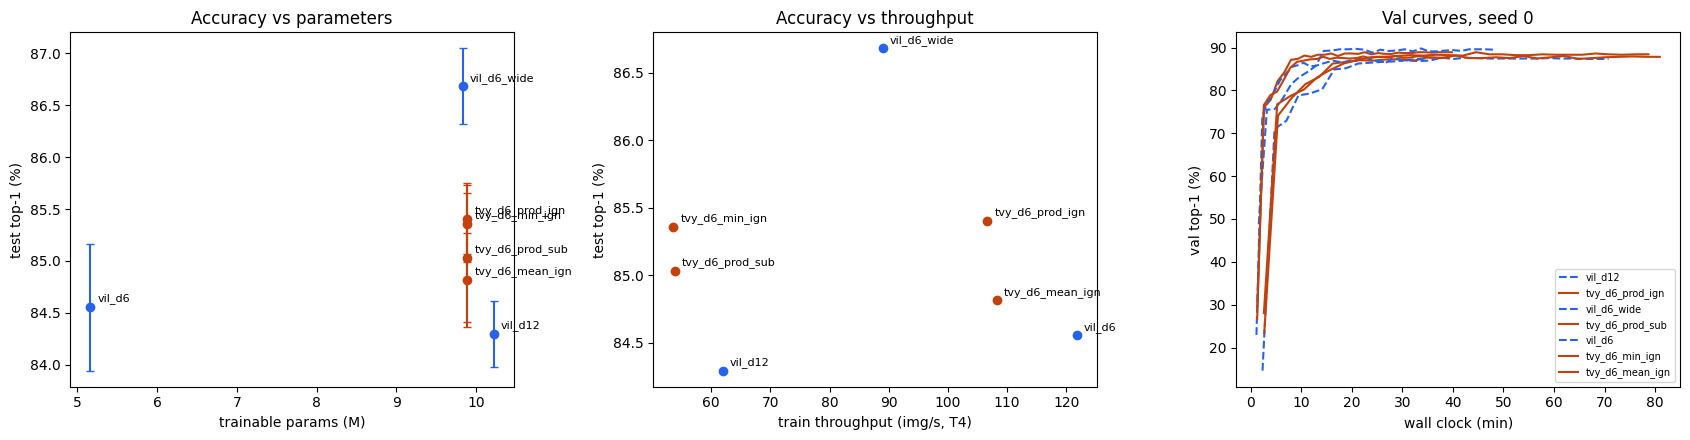

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
colors = {n: ("#c2410c" if n.startswith("tvy") else "#2563eb") for n in order}

ax = axes[0]
for n in order:
    a = agg.loc[n]
    ax.errorbar(a.params / 1e6, a.test_top1, yerr=0 if np.isnan(a.test_top1_std) else a.test_top1_std,
                fmt="o", color=colors[n], capsize=3)
    ax.annotate(n, (a.params / 1e6, a.test_top1), textcoords="offset points", xytext=(5, 4), fontsize=8)
ax.set_xlabel("trainable params (M)"); ax.set_ylabel("test top-1 (%)"); ax.set_title("Accuracy vs parameters")

ax = axes[1]
for n in order:
    a = agg.loc[n]
    ax.scatter(a.train_ips, a.test_top1, color=colors[n])
    ax.annotate(n, (a.train_ips, a.test_top1), textcoords="offset points", xytext=(5, 4), fontsize=8)
ax.set_xlabel("train throughput (img/s, T4)"); ax.set_ylabel("test top-1 (%)"); ax.set_title("Accuracy vs throughput")

ax = axes[2]
for r in rows:
    if r["seed"] == min(SEEDS):
        h = pd.DataFrame(r["history"])
        ax.plot(h.elapsed_s / 60, h.val_top1, label=r["arm"], color=colors.get(r["arm"], "gray"),
                ls="-" if r["arm"].startswith("tvy") else "--")
ax.set_xlabel("wall clock (min)"); ax.set_ylabel("val top-1 (%)"); ax.set_title(f"Val curves, seed {min(SEEDS)}")
ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "vision_results.png"), dpi=150); plt.show()

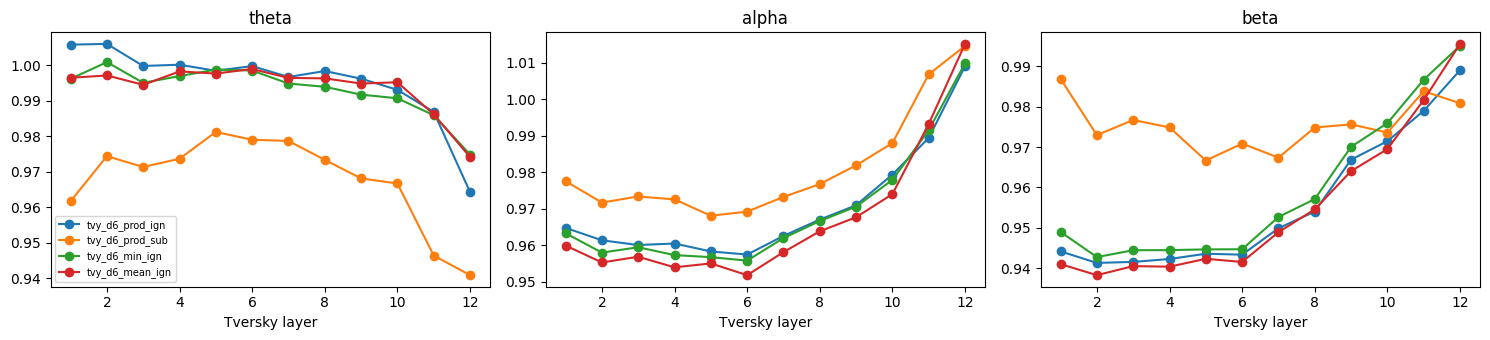

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharex=True)
for r_arm in [n for n in order if n.startswith("tvy")]:
    cs = np.array([r["constants"] for r in rows if r["arm"] == r_arm])   # (seeds, layers, 3)
    if cs.size == 0:
        continue
    m = cs.mean(0)
    for j, name in enumerate(["theta", "alpha", "beta"]):
        axes[j].plot(range(1, len(m) + 1), m[:, j], marker="o", label=r_arm)
        axes[j].set_title(name); axes[j].set_xlabel("Tversky layer")
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "vision_constants.png"), dpi=150); plt.show()